---
title: "Wycena opcji barierowej Down-and-Out Put za pomocą PyMPDATA"
author: "Kamil Kasperek"
lang: pl
format:
  pdf:
    geometry: margin=0.55in
    fontsize: 9.5pt
    echo: false
    warning: false
---

### Cel pracy i pytanie badawcze
Celem eksperymentu jest numeryczna wycena europejskiej opcji sprzedaży z dolną barierą wyłączającą (**Down-and-Out Put**) poprzez sprowadzenie modelu Blacka-Scholesa do równania adwekcji-dyfuzji i rozwiązanie go za pomocą biblioteki `PyMPDATA`. 

**Pytanie badawcze:** *Jak dobrze schemat 2. rzędu `MPDATA` radzi sobie ze stromym spadkiem wartości przy barierze $B$ oraz wyznaczeniem współczynnika Delta ($\Delta = \partial V / \partial S$) na różnych rozdzielczościach siatki w porównaniu ze zwykłym schematem `upwind`?*

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PyMPDATA-examples')

In [2]:
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.special import erf

## 1. Czym jest opcja Down-and-Out Put?
Opcja *Down-and-Out Put* to opcja sprzedaży z dolną barierą wyłączającą. Daje prawo do sprzedaży akcji po ustalonej cenie wykonania (np. $K = 120\$$), pod warunkiem że kurs akcji w trakcie trwania umowy nie spadnie do poziomu bariery ($B = 80\$$) lub poniżej niej. Jeśli kurs dotknie bariery, opcja natychmiast wygasa jako bezwartościowa.

## 2. Numeryka i rozwiązanie analityczne
Równanie Blacka-Scholesa po przejściu na zmienną logarytmiczną $x = \ln(S/K)$ oraz czas wsteczny $\tau = T - t$ przyjmuje postać jednowymiarowego równania adwekcji-dyfuzji, gdzie dyfuzja odpowiada zmienności $\sigma$, a adwekcja dryfowi rynkowemu. Barierę wyłączającą $B$ modelujemy jako pochłaniający warunek brzegowy Dirichleta ($\psi = 0$ dla $S \le B$).

Jako punkt odniesienia wykorzystano ścisły [wzór analityczny](https://people.maths.ox.ac.uk/howison/barriers.pdf).

In [3]:
class DownAndOutPutIntegrator:
    def __init__(self, *, strike_price, barrier_price, volatility, risk_free_interest_rate, nx, options=None):
        options = options or Options(nonoscillatory=True, infinite_gauge=False, non_zero_mu_coeff=True)

        assert options.non_zero_mu_coeff, "non_zero_mu_coeff must be True"
        assert strike_price > 0
        assert barrier_price > 0
        assert risk_free_interest_rate >= 0
        assert volatility >= 0
        assert nx > 0

        self.K = strike_price
        self.B = barrier_price
        self.r = risk_free_interest_rate
        self.sigma = volatility

        x_min = np.log(self.B / self.K)
        x_max = max(4.0 * np.log(self.K / self.B), 1.5)
        self.dx = (x_max - x_min) / nx
        self.S = self.K * np.exp(x_min + (np.arange(nx) + 0.5) * self.dx)
        self.payout = np.where((self.B < self.S) & (self.S < self.K), self.K - self.S, 0.0)

        common = {
            'halo': options.n_halo,
            'boundary_conditions': (boundary_conditions.Constant(value=0),)
        }

        self.advectee = ScalarField(**common, data=self.payout.copy())
        self.advector = VectorField(**common, data=(np.zeros(nx + 1),))
        self.solver = Solver(
            advector=self.advector,
            advectee=self.advectee,
            stepper=Stepper(n_dims=1, options=options)
        )

    def __call__(self, *, nt, T, outfreq):
        assert nt % outfreq == 0, "nt must be divisible by outfreq"
        
        dt = T / nt
        c_adv = (0.5 * self.sigma**2 - self.r) * dt / self.dx
        mu = 0.5 * self.sigma**2 * dt / (self.dx**2)
        assert abs(c_adv) + 2 * mu <= 1.0

        self.advectee.get()[:] = self.payout
        self.advector.get_component(0)[:] = c_adv

        output = [self.advectee.get().copy()]
        for step in range(1, nt // outfreq + 1):
            self.solver.advance(n_steps=outfreq, mu_coeff=(mu,))
            output.append(self.advectee.get().copy() * np.exp(-self.r * step * outfreq * dt))
        return output

In [4]:
def AnalyticalDownAndOutPutSolver(S, K, B, T, r, sigma):
    def N(z):
        return 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

    def vanilla_put(s, strike):
        d1 = (np.log(s / strike) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        return strike * np.exp(-r * T) * N(-d2) - s * N(-d1)

    def binary_put(s, strike):
        d2 = (np.log(s / strike) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        return np.exp(-r * T) * N(-d2)

    def truncated_put(s):
        return vanilla_put(s, K) - vanilla_put(s, B) - (K - B) * binary_put(s, B)

    power = 2.0 * r / (sigma**2) - 1.0
    result = truncated_put(S) - (B / S)**power * truncated_put((B**2) / S)
    return np.where(S > B, result, 0.0)

In [5]:
def pad_barrier(S_arr, V_arr, barrier, s_min=60.0):
    return np.concatenate(([s_min, barrier], S_arr)), np.concatenate(([0.0, 0.0], V_arr))

In [6]:
def plot_results(integ_MPDATA, output_MPDATA, output_upwind, S_fine, analytical_price, analytical_delta, nx, nt):
    S = integ_MPDATA.S
    barrier = integ_MPDATA.B
    S_plot, payoff_plot = pad_barrier(S, output_MPDATA[0], barrier)
    _, mpdata_mid = pad_barrier(S, output_MPDATA[len(output_MPDATA) // 2], barrier)
    _, upwind_mid = pad_barrier(S, output_upwind[len(output_upwind) // 2], barrier)
    _, upwind_end = pad_barrier(S, output_upwind[-1], barrier)
    _, mpdata_end = pad_barrier(S, output_MPDATA[-1], barrier)
    S_fine_plot, exact_plot = pad_barrier(S_fine, analytical_price, barrier)

    mpdata_delta = np.gradient(output_MPDATA[-1], S)
    upwind_delta = np.gradient(output_upwind[-1], S)

    fig, (ax_price, ax_delta) = pyplot.subplots(1, 2, figsize=(11, 3.5))

    ax_price.plot(S_plot, payoff_plot, linestyle=':', color='gray', label='Payoff (t = T)')
    ax_price.plot(S_plot, mpdata_mid, linestyle='-.', color='tab:cyan', label='MPDATA (t = 0.5 T)')
    ax_price.plot(S_plot, upwind_mid, linestyle='-.', color='tab:orange', label='upwind (t = 0.5 T)')
    ax_price.plot(S_plot, upwind_end, linestyle='--', color='tab:red', label='upwind (t = 0)')
    ax_price.plot(S_plot, mpdata_end, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_price.plot(S_fine_plot, exact_plot, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')

    ax_delta.plot(S, upwind_delta, linestyle='--', color='tab:orange', label='upwind (t = 0)')
    ax_delta.plot(S, mpdata_delta, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_delta.plot(S_fine, analytical_delta, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_delta.axhline(0, color='gray', linewidth=0.8)

    for ax, ylabel, title in [
        (ax_price, 'Option value V(S, t) [$]', f'Option value evolution (nx={nx}, nt={nt})'),
        (ax_delta, 'Delta Δ = ∂V / ∂S [-]', f'Portfolio sensitivity: Delta (nx={nx}, nt={nt})')
    ]:
        ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier}$')
        ax.set_xlim(75, 160)
        ax.set_xlabel('Asset price S [$]')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.3)

    ax_price.legend(fontsize=7.5, ncol=2)
    ax_delta.legend(fontsize=7.5)
    pyplot.tight_layout()
    pyplot.show()

In [7]:
def run_scenario(*, integ_MPDATA, integ_upwind, nt, T, outfreq, analytical_price):
    
    output_MPDATA = integ_MPDATA(nt=nt, T=T, outfreq=outfreq)
    output_upwind = integ_upwind(nt=nt, T=T, outfreq=outfreq)

    assert np.all(output_MPDATA[-1] >= 0.0), "Price of asset cannot be negative"
    assert np.all(output_upwind[-1] >= 0.0), "Price of asset cannot be negative"
    
    exact = np.interp(integ_MPDATA.S, S_fine, analytical_price, right=0.0)
    error_mpdata = (np.sqrt(np.mean((output_MPDATA[-1] - exact)**2)))
    error_upwind = (np.sqrt(np.mean((output_upwind[-1] - exact)**2)))
    
    return output_MPDATA, output_upwind, error_mpdata, error_upwind

## 3. Wyniki symulacji dla różnych rozdzielczości siatki

Przetestowano półroczną opcję ($T = 0{,}5\text{ roku}$) o cenie wykonania $K = 120\$$, barierze $B = 80\$$, zmienności $\sigma = 35\%$ i stopie wolnej od ryzyka $r = 5\%$ dla czterech coraz gęstszych siatek przestrzennych $n_x \in \{50, 100, 150, 200\}$ oraz siatek czasowych $n_t \in \{1600, 3200, 6400\}$. Wyznaczono ich błędy względem wzoru teoreycznego i przedstawiono wynik ceny opcji oraz jego współczynnik delty dla najdokładniejszej siatki.

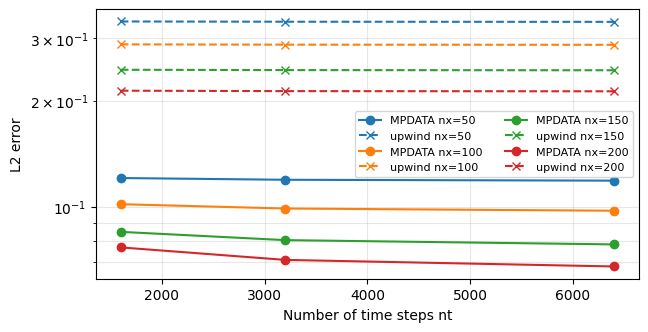

In [8]:
strike_price = 120
barrier_price = 80
volatility = 0.35
risk_free_interest_rate = 0.05
T = 0.5
nx = [50, 100, 150, 200]
nt = [1600, 3200, 6400]

S_fine = np.linspace(barrier_price, 200.0, 1000)
analytical_price = AnalyticalDownAndOutPutSolver(S_fine, strike_price, barrier_price, T, risk_free_interest_rate, volatility)
analytical_delta = np.gradient(analytical_price, S_fine)

errors_mpdata = np.empty((len(nx), len(nt)))
errors_upwind = np.empty((len(nx), len(nt)))

for i, nx_i in enumerate(nx):
    integ_MPDATA = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx_i
    )
    integ_upwind = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx_i, options=Options(n_iters=1, non_zero_mu_coeff=True)
    )
    for j, nt_i in enumerate(nt):
        _, _, errors_mpdata[i, j], errors_upwind[i, j] = run_scenario(
            integ_MPDATA=integ_MPDATA, integ_upwind=integ_upwind,
            nt=nt_i, T=T, outfreq=nt_i, analytical_price=analytical_price
        )

assert np.all(errors_mpdata < errors_upwind), "MPDATA should beat upwind on all grids"
assert errors_mpdata[-1, -1] < 0.1, f"Finest grid error too large: {errors_mpdata[-1, -1]:.4f}"
assert np.all(np.diff(errors_mpdata, axis=0) < 0), "Error must strictly decrease with finer nx"
assert np.all(np.diff(errors_mpdata, axis=1) < 0), "Error must strictly decrease with finer nt"

fig, ax = pyplot.subplots(figsize=(7, 3.5))
for i, nx_val in enumerate(nx):
    ax.plot(nt, errors_mpdata[i], f'C{i}o-', label=f'MPDATA nx={nx_val}')
    ax.plot(nt, errors_upwind[i], f'C{i}x--', label=f'upwind nx={nx_val}')
ax.set_yscale('log')
ax.set_xlabel('Number of time steps nt')
ax.set_ylabel('L2 error')
ax.grid(True, which='both', alpha=0.3)
ax.legend(ncol=2, fontsize=8)
pyplot.show()

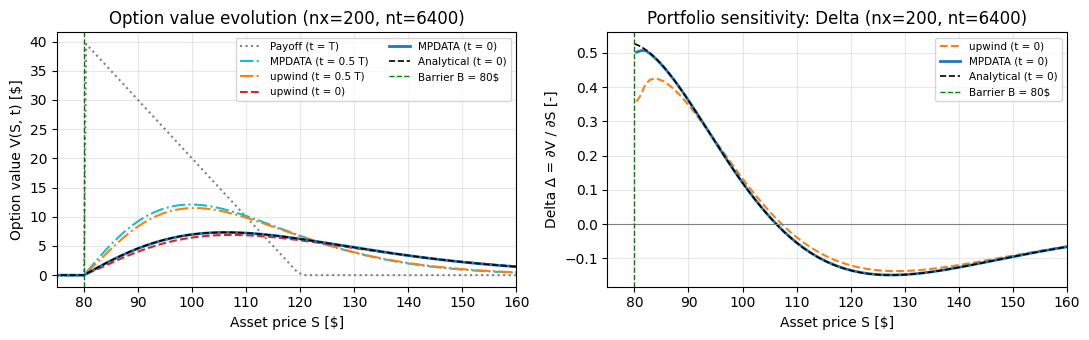

In [9]:
integ_MPDATA = DownAndOutPutIntegrator(
            strike_price=strike_price, barrier_price=barrier_price,
            volatility=volatility,
            risk_free_interest_rate=risk_free_interest_rate, nx=nx[-1], 
            options=Options(nonoscillatory=True, infinite_gauge=True, non_zero_mu_coeff=True)
            )
integ_upwind = DownAndOutPutIntegrator(
            strike_price=strike_price, barrier_price=barrier_price,
            volatility=volatility, 
            risk_free_interest_rate=risk_free_interest_rate, nx=nx[-1], 
            options=Options(n_iters=1, non_zero_mu_coeff=True)
            )

output_MPDATA, output_upwind, error_mpdata, error_upwind = run_scenario(integ_MPDATA=integ_MPDATA, integ_upwind=integ_upwind, 
                                                  nt=nt[-1], T=T, outfreq=20, analytical_price=analytical_price)

plot_results(integ_MPDATA, output_MPDATA, output_upwind, S_fine, analytical_price, analytical_delta, nx[-1], nt[-1])

## 4 Animacje

Wygenerowano animację dla poprzedniego przypadku. Dodatkowo zbadano inny niecodzienny scenariusz, aby odkryć co się stanie, gdy ciecz ekonomiczna popłynie prosto w kierunku bariery z praktycznie zerową dyfuzją. Pozostawiono takie same ceny sprzedaży i bariery, okres czasu, a zmieniono stopę oprocentownie na $r=0.30$ oraz volatilit $\sigma =0.01$.

In [10]:
from matplotlib.animation import FuncAnimation, PillowWriter

def save_animation(*, name, integ_MPDATA, output_MPDATA, output_upwind, analytical_price):
    barrier_price = integ_MPDATA.B
    dt_frame = T / (len(output_MPDATA) - 1)
    y_max = np.max(output_MPDATA[0]) * 1.1
    S_plot, _ = pad_barrier(integ_MPDATA.S, output_MPDATA[0], barrier_price)
    S_fine_plot, exact_plot = pad_barrier(S_fine, analytical_price, barrier_price)
    
    fig, ax = pyplot.subplots(figsize=(7, 4))
    
    def update(frame):
        ax.clear()
        t_remaining = T - frame * dt_frame
        _, mpdata_frame = pad_barrier(integ_MPDATA.S, output_MPDATA[frame], barrier_price)
        _, upwind_frame = pad_barrier(integ_MPDATA.S, output_upwind[frame], barrier_price)
    
        ax.fill_between(S_plot, mpdata_frame, color='tab:blue', alpha=0.25)
        ax.plot(S_plot, mpdata_frame, color='tab:blue', linewidth=2, label='MPDATA')
        ax.plot(S_plot, upwind_frame, color='tab:orange', linestyle='--', linewidth=1.5, label='upwind')
        ax.plot(S_fine_plot, exact_plot, color='black', linestyle=':', linewidth=1.2, label='Analytical (t = 0)')
        ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1.5, label=f'Barrier B = {barrier_price}$')
        ax.set_xlim(65, 200)
        ax.set_ylim(-1, y_max)
        ax.set_xlabel('Asset price S [$]')
        ax.set_ylabel('Option value V(S, t) [$]')
        ax.set_title(f'Option value evolution (nx=125, nt=1000) – {t_remaining:.3f} years remaining')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right')
    
    anim = FuncAnimation(fig, update, frames=len(output_MPDATA), interval=80)
    anim.save(name, writer=PillowWriter(fps=15))
    pyplot.close(fig)

In [11]:
save_animation(name="standard_animation.gif", integ_MPDATA=integ_MPDATA, output_MPDATA=output_MPDATA,
               output_upwind=output_upwind, analytical_price=analytical_price)

In [12]:
strike_price = 120
barrier_price = 80
volatility = 0.01
risk_free_interest_rate = 0.30
T = 0.5
nx = 200
nt = 6400
outfreq = 20

integ_MPDATA = DownAndOutPutIntegrator(
            strike_price=strike_price, barrier_price=barrier_price,
            volatility=volatility,
            risk_free_interest_rate=risk_free_interest_rate, nx=nx, 
            options=Options(nonoscillatory=True, infinite_gauge=True, non_zero_mu_coeff=True)
            )
integ_upwind = DownAndOutPutIntegrator(
            strike_price=strike_price, barrier_price=barrier_price,
            volatility=volatility, 
            risk_free_interest_rate=risk_free_interest_rate, nx=nx, 
            options=Options(n_iters=1, non_zero_mu_coeff=True)
            )

S_fine = np.linspace(barrier_price, 200.0, 1000)
analytical_price = AnalyticalDownAndOutPutSolver(S_fine, strike_price, barrier_price, T, risk_free_interest_rate, volatility)

output_MPDATA, output_upwind, _, _ = run_scenario(integ_MPDATA=integ_MPDATA, integ_upwind=integ_upwind, 
                                                  nt=nt, T=T, outfreq=outfreq, analytical_price=analytical_price)

save_animation(name="left_advection_animation.gif", integ_MPDATA=integ_MPDATA, output_MPDATA=output_MPDATA, 
               output_upwind=output_upwind, analytical_price=analytical_price)

### Wnioski
- **Zbieżność na siatce:** Po wykresie błędów w zależności od dokładności siatki przestrzennej oraz czasowej widać, że im większa jest liczba kroków czasowych lub podziałki siatki, to błąd jest coraz mniejszy. Też warto zwrócić uwagę na to, że trzeba pamiętać o tym, aby nt i nx było odpowiednio dobrane, teraz w kodzie jest assert c_adv + 2mu <= 1, ale to może byc za mało ze względu na inditite gauge = true oraz non oscilatory = true ale tego nie jestem pewien
- **Zachowanie Delty przy samej barierze:** Tuż przy barierze ($S \to B^+$) widać dla obu schematów lokalne odchylenie od krzywej analitycznej (wynikające z ostrego warunku brzegowego $\psi = 0$ i numerycznego różniczkowania na krawędzi siatki). Schemat `upwind` wyraźnie traci tu dokładność, natomiast `MPDATA` bardzo dobrze odtwarza przebieg $\Delta$, wykazując jedynie niewielkie zniekształcenie brzegowe w pierwszej komórce przy barierze.
- **Animajce:** Animacja standardowego scenariuszu ekonomicznego pokazuje bardzo dobrze lekką adwekcję w prawą stronę, silną dyfuzję oraz świetne pokrycie z wynikiem analitycznym. Też warto zwrócić uwagę, że MPDTA sobie radzi zdecydowanie lepiej niż upwind - w upwind widać więcej dyfuzji numerycznej. Co do scenariuszu niestandardwoeg, widać że tez sobie lepiej radzi, aczkowliek szczególie przy MPDATA widać lekkie pofalowania. Upwind bardzo dobrze sobie radzi, z początku by się wydawało że tak samo dobrze, ale po prawej stronie wyreksu widać że upwindma większe odstępsta. Aczkowlkek i tak, na obu animacjach bardzo ładnie widać zachowanie cieczy, oraz jak ta ciecz "wylewa" się z prawej strony, przy baruerze cenowej.